# More Pandas Practice: Combining Data, Binning, and Pivot Tables

This notebook gives you practice applying the tools from `02_Combining_Dataframes.ipynb`: joining and concatenating DataFrames with `.join()` and `pd.concat()`, binning continuous data into categories with `pd.cut()`, and summarising data with `pd.pivot_table()`. You will work with the red and white wine quality datasets throughout, loading, combining, filtering, and pivoting them to answer realistic data questions.

---

## Starter Code

In [1]:
# Import pandas and load both wine datasets, run this cell first
import pandas as pd

red_df = pd.read_csv("../data/winequality-red.csv", delimiter=";")
white_df = pd.read_csv("../data/winequality-white.csv", delimiter=";")

print("Red wine shape:", red_df.shape)
print("White wine shape:", white_df.shape)

Red wine shape: (1599, 12)
White wine shape: (4898, 12)


---

## Part 1: Loading and Inspecting

### Challenge 1: Sense-check the data

Use DataFrame attributes and methods to confirm both datasets loaded correctly. Check:

- The number of rows and columns in each

- The data types of the columns

- Whether any columns contain null values

In [2]:
for name, frame in [("Red", red_df), ("White", white_df)]:
    print(name, "shape:", frame.shape)
    # value_counts of dtypes: how many columns of each type
    print(frame.dtypes.value_counts().to_dict())
    print("Missing values in total:", frame.isna().sum().sum())
    print()

Red shape: (1599, 12)
{dtype('float64'): 11, dtype('int64'): 1}
Missing values in total: 0

White shape: (4898, 12)
{dtype('float64'): 11, dtype('int64'): 1}
Missing values in total: 0



**My answer:** red has 1599 rows, white 4898; both have the same 12 columns (11 `float64` + `quality` as `int64`)
and no missing values. Both files loaded correctly.

---

## Part 2: Filtering by Alcohol Content

### Challenge 2: Flag above-average alcohol

You want to avoid wines with above-average alcohol content. To do this:

1. Find the **mean alcohol content** separately for reds and whites.

2. Create a **boolean `Series`** for each DataFrame indicating whether each row has an alcohol content above the mean.

3. Attach this boolean `Series` to each DataFrame, do it **twice**: once using `.join()` and once using `pd.concat(..., axis=1)`.

4. Filter each DataFrame to return only the rows where alcohol is **above** the mean.

In [3]:
# Step 1: Calculate mean alcohol for each wine type
red_mean_alcohol = red_df["alcohol"].mean()
white_mean_alcohol = white_df["alcohol"].mean()
print("Red mean alcohol:  ", round(red_mean_alcohol, 3))
print("White mean alcohol:", round(white_mean_alcohol, 3))

Red mean alcohol:   10.423
White mean alcohol: 10.514


In [4]:
# Step 2: Create boolean Series, True where alcohol is above the mean
# Compare every row with its own wine type's mean; name the Series
red_above_flag = (red_df["alcohol"] > red_mean_alcohol).rename(
    "above_mean_alcohol")
white_above_flag = (white_df["alcohol"] > white_mean_alcohol).rename(
    "above_mean_alcohol")
red_above_flag.head()

0    False
1    False
2    False
3    False
4    False
Name: above_mean_alcohol, dtype: bool

In [5]:
# Step 3a: Attach using .join()
# .join lines the flag up with the rows by index
red_joined = red_df.join(red_above_flag)
white_joined = white_df.join(white_above_flag)
red_joined.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,above_mean_alcohol
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,False
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,False
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,False
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,False
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,False


In [6]:
# Step 3b: Attach using pd.concat(..., axis=1)
# Same result with concat side by side (axis=1)
red_concat = pd.concat([red_df, red_above_flag], axis=1)
white_concat = pd.concat([white_df, white_above_flag], axis=1)
print("Same as join:", red_concat.equals(red_joined),
      white_concat.equals(white_joined))

Same as join: True True


In [7]:
# Step 4: Filter to only rows where alcohol is above the mean
# A boolean column can be used directly as the filter
red_above = red_joined[red_joined["above_mean_alcohol"]]
white_above = white_joined[white_joined["above_mean_alcohol"]]
print("Red above mean:  ", len(red_above), "of", len(red_df))
print("White above mean:", len(white_above), "of", len(white_df))

Red above mean:   683 of 1599
White above mean: 2163 of 4898


**Note:** the story says we want to *avoid* above-average alcohol, but step 4 and Challenge 4 ask for the
above-mean rows, so I follow the steps. The wines to keep would be the opposite filter:
`red_joined[~red_joined["above_mean_alcohol"]]` (`~` flips True and False).

---

## Part 3: Binning by Acidity

### Challenge 3: Bin by fixed acidity

You want to avoid wines with the highest acidity. To do this:

1. Use `pd.cut()` to divide the `fixed acidity` column of each DataFrame into **5 equal-width bins**.

2. Attach the resulting bin `Series` to each original DataFrame, once using `.join()` and once using `pd.concat(..., axis=1)`.

3. Filter each DataFrame to return only rows that are **not** in the top acidity bin.

> Note: equal-width bins divide the *range* of values into equal intervals. They are different from quintiles (equal-count bins).

In [8]:
# Step 1: Create 5 equal-width acidity bins for red and white wines
# bins=5 splits each value range into 5 intervals of equal width
red_acidity_bin = pd.cut(red_df["fixed acidity"], bins=5).rename(
    "acidity_bin")
white_acidity_bin = pd.cut(white_df["fixed acidity"], bins=5).rename(
    "acidity_bin")
print(red_acidity_bin.value_counts().sort_index())
print(white_acidity_bin.value_counts().sort_index())

acidity_bin
(4.589, 6.86]     274
(6.86, 9.12]      913
(9.12, 11.38]     298
(11.38, 13.64]    102
(13.64, 15.9]      12
Name: count, dtype: int64
acidity_bin
(3.79, 5.88]       471
(5.88, 7.96]      3953
(7.96, 10.04]      467
(10.04, 12.12]       6
(12.12, 14.2]        1
Name: count, dtype: int64


In [9]:
# Step 2a: Attach bins using .join()
red_binned = red_df.join(red_acidity_bin)
white_binned = white_df.join(white_acidity_bin)
red_binned.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,acidity_bin
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,"(6.86, 9.12]"
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,"(6.86, 9.12]"
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,"(6.86, 9.12]"
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,"(9.12, 11.38]"
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,"(6.86, 9.12]"


In [10]:
# Step 2b: Attach bins using pd.concat(..., axis=1)
red_binned_concat = pd.concat([red_df, red_acidity_bin], axis=1)
white_binned_concat = pd.concat([white_df, white_acidity_bin], axis=1)
print("Same as join:", red_binned_concat.equals(red_binned),
      white_binned_concat.equals(white_binned))

Same as join: True True


In [11]:
# Step 3: Filter out the top acidity bin from each DataFrame
# The bin categories are sorted low to high: the last one is the top bin
red_top = red_binned["acidity_bin"].cat.categories[-1]
white_top = white_binned["acidity_bin"].cat.categories[-1]
red_not_top = red_binned[red_binned["acidity_bin"] != red_top]
white_not_top = white_binned[white_binned["acidity_bin"] != white_top]
print("Red: top bin", red_top, "| rows kept", len(red_not_top))
print("White: top bin", white_top, "| rows kept", len(white_not_top))

Red: top bin (13.64, 15.9] | rows kept 1587
White: top bin (12.12, 14.2] | rows kept 4897


**Note:** equal-width bins are very uneven here. Red's top bin holds only 12 wines, white's only 1,
because a few extreme values stretch the range. Equal-count bins (`pd.qcut`) would cut off far more wines.

---

## Part 4: Pivot Tables

### Challenge 4: Alcohol by quality, pivot table

You want to understand how avoiding above-average alcohol affects the quality of wines available to you.

Using the **above-average alcohol** subsets from Challenge 2, create a **pivot table** for each wine type showing:

- The **average `alcohol` content** as the value

- **`quality`** as the index

This should give you one row per quality level and the average alcohol content for that group.

In [12]:
# Pivot table for red wines above mean alcohol, average alcohol by quality
red_pivot = pd.pivot_table(red_above, values="alcohol",
                           index="quality", aggfunc="mean")
red_pivot

,alcohol
quality,
3,10.866667
4,11.295000
5,11.088686
6,11.437214
7,11.708236
8,12.368750


In [13]:
# Pivot table for white wines above mean alcohol, average alcohol by quality
white_pivot = pd.pivot_table(white_above, values="alcohol",
                             index="quality", aggfunc="mean")
white_pivot

,alcohol
quality,
3,11.525000
4,11.425532
5,11.211099
6,11.604366
7,11.924761
8,12.139437
9,12.625000


### Challenge 5: Alcohol by quality and acidity bin, pivot table

Now do the same for the **non-top-acidity** subsets from Challenge 3. Create a pivot table for each wine type showing:

- The **average `alcohol` content** as the value

- **`quality`** as the index

- **`fixed acidity` bin** as the columns

This lets you see average alcohol broken down by both quality score and acidity category.

In [14]:
# Pivot table for red wines, average alcohol by quality and acidity bin
red_pivot2 = pd.pivot_table(red_not_top, values="alcohol",
                            index="quality", columns="acidity_bin",
                            aggfunc="mean")
red_pivot2.round(2)

acidity_bin,"(4.589, 6.86]","(6.86, 9.12]","(9.12, 11.38]","(11.38, 13.64]"
quality,,,,
3,9.88,10.50,9.15,9.00
4,11.01,9.98,9.92,9.97
5,10.30,9.77,9.85,10.23
6,11.22,10.43,10.69,10.48
7,12.20,11.49,11.38,10.81
8,13.63,11.94,11.92,9.80


In [15]:
# Pivot table for white wines, average alcohol by quality and acidity bin
white_pivot2 = pd.pivot_table(white_not_top, values="alcohol",
                              index="quality", columns="acidity_bin",
                              aggfunc="mean")
white_pivot2.round(2)

acidity_bin,"(3.79, 5.88]","(5.88, 7.96]","(7.96, 10.04]","(10.04, 12.12]"
quality,,,,
3,9.85,10.47,10.54,9.65
4,10.79,10.10,10.13,9.90
5,10.14,9.73,10.18,9.70
6,10.90,10.53,10.64,9.50
7,12.02,11.30,10.99,NaN
8,12.40,11.49,11.08,NaN
9,NaN,12.62,10.40,NaN


**My reading:** in both tables, higher quality comes with higher average alcohol, in almost every acidity bin.
Empty cells (`NaN`) mean no wine has that combination (for example, no white wine of quality 9 in the lowest acidity bin).

---

## Part 5: Open Exploration

### Challenge 6: Your own question

Set a 10-minute timer. Pick one question about the wine data that interests you and answer it using any combination of the tools from this notebook (filtering, joining, binning, pivot tables, groupby, visualisation). Be ready to explain what you found and why you chose that question.

type          red  white
alcohol_bin             
8-9           0.0   14.3
9-10          3.0    5.4
10-11        12.4   18.8
11-12        28.1   34.2
12-13        46.6   50.6
13+          47.8   65.7
type         red  white
alcohol_bin            
8-9           37    502
9-10         710   1583
10-11        444   1252
11-12        267    850
12-13        118    609
13+           23    102


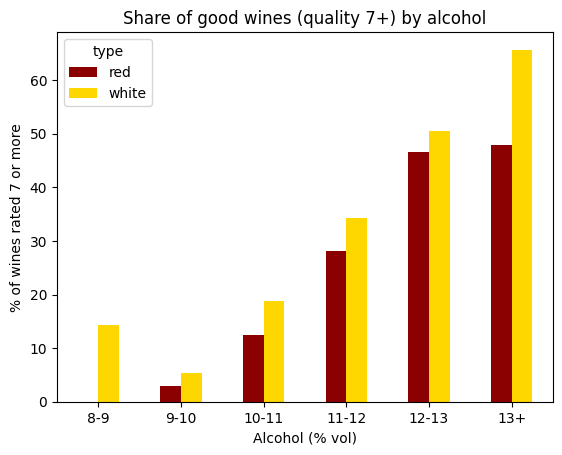

In [16]:
# matplotlib is not loaded in this notebook yet
import matplotlib.pyplot as plt

# My question: are good wines (quality 7+) more common at higher
# alcohol, and is that true for both red and white?
wine = pd.concat([red_df.assign(type="red"),
                  white_df.assign(type="white")], ignore_index=True)

# Alcohol in 1-point bins; 7.9 as the first edge so 8.0 is included
wine["alcohol_bin"] = pd.cut(
    wine["alcohol"], bins=[7.9, 9, 10, 11, 12, 13, 15],
    labels=["8-9", "9-10", "10-11", "11-12", "12-13", "13+"])
wine["good"] = wine["quality"] >= 7

# Mean of True/False = share of True; x100 for percent
share_good = pd.pivot_table(wine, values="good", index="alcohol_bin",
                            columns="type", aggfunc="mean") * 100
print(share_good.round(1))
print(pd.crosstab(wine["alcohol_bin"], wine["type"]))

share_good.plot(kind="bar", rot=0, color=["darkred", "gold"],
                title="Share of good wines (quality 7+) by alcohol")
plt.ylabel("% of wines rated 7 or more")
plt.xlabel("Alcohol (% vol)")
plt.show()

**What I found:** yes, strongly. Among wines with 9-10 % alcohol only about 3 % (red) and 5 % (white) are rated 7+;
at 12-13 % it is about 47 % and 51 %. Overall 13.6 % of reds and 21.6 % of whites are "good".
Caution: the 8-9 % and 13+ groups are small (37 and 23 red wines), and this is a correlation, not proof
that alcohol *causes* better ratings.